# EMQA_L5_hedge_scatter

**Minimum-variance hedge ratio, Romania versus Hungary and Germany**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_hedge_scatter/EMQA_L5_hedge_scatter.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Monthly changes of the Romanian price regressed on those of Hungary and Germany: the slope is the hedge ratio h*.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
# monthly mean day-ahead prices, kept only for months with every day present
m_idx = pd.date_range('2015-01-01', END.replace(day=1), freq='MS')
PM = PD[['RO', 'HU', 'DE_LU']].resample('MS').mean().reindex(m_idx)
NDM = PD[['RO', 'HU', 'DE_LU']].resample('MS').count().reindex(m_idx)
PM = PM.where(NDM.eq(pd.Series(m_idx.days_in_month, index=m_idx), axis=0))

In [5]:
import statsmodels.api as sm
SEED = 20261106


def hedge_ratio(dS, dF, B=2000, block=6, seed=SEED):
    """h* = Cov(dS, dF)/Var(dF) by OLS; HAC (Newey-West, 3 lags) standard error; moving-block bootstrap 95% interval."""
    X = sm.add_constant(dF.values)
    r = sm.OLS(dS.values, X).fit(cov_type='HAC', cov_kwds={'maxlags': 3})
    rng = np.random.default_rng(seed)
    n = len(dS)
    hs = []
    for _ in range(B):
        idx = np.concatenate([np.arange(s, s + block) for s in rng.integers(0, n - block + 1, size=n // block + 1)])[:n]
        a, b = dS.values[idx], dF.values[idx]
        hs.append(np.cov(a, b)[0, 1] / np.var(b, ddof=1))
    lo, hi = np.percentile(hs, [2.5, 97.5])
    return {'h': float(r.params[1]), 'se': float(r.bse[1]), 'lo': float(lo), 'hi': float(hi), 'r2': float(r.rsquared),
            'rho': float(np.corrcoef(dS, dF)[0, 1]), 'n': int(n)}


dP = PM.diff().dropna()          # monthly changes of the monthly mean prices
HR = {}
for z in ['HU', 'DE_LU']:
    HR[z] = hedge_ratio(dP['RO'], dP[z])
    ins, oos = dP.loc[:'2020-12-01'], dP.loc['2021-01-01':]
    h_in = hedge_ratio(ins['RO'], ins[z])          # estimated on 2015-2020, applied from 2021
    v0 = oos['RO'].var()
    HR[z]['h_in'] = h_in['h']
    HR[z]['vr_oos_h'] = 100 * (1 - (oos['RO'] - h_in['h'] * oos[z]).var() / v0)
    HR[z]['vr_oos_1'] = 100 * (1 - (oos['RO'] - oos[z]).var() / v0)

print('monthly changes', dP.index.min().strftime('%Y-%m'), 'to', dP.index.max().strftime('%Y-%m'), '; n =', len(dP))
for z, nm in [('HU', 'Hungary'), ('DE_LU', 'Germany')]:
    show(f'{nm}: h*', HR[z]['h'], f'hedge.{z}.h', '.3f')
    show(f'{nm}: HAC standard error', HR[z]['se'], f'hedge.{z}.se', '.3f')
    show(f'{nm}: bootstrap 95% lower bound', HR[z]['lo'], f'hedge.{z}.lo', '.2f')
    show(f'{nm}: bootstrap 95% upper bound', HR[z]['hi'], f'hedge.{z}.hi', '.2f')
    show(f'{nm}: R2 (hedge effectiveness)', HR[z]['r2'], f'hedge.{z}.r2', '.2f')
    show(f'{nm}: h* estimated on 2015-2020', HR[z]['h_in'], f'hedge.{z}.h_in', '.2f')
    show(f'{nm}: variance removed from 2021 with that h*, %', HR[z]['vr_oos_h'], f'hedge.{z}.vr_oos_h', '.1f')
    show(f'{nm}: variance removed from 2021 with h = 1, %', HR[z]['vr_oos_1'], f'hedge.{z}.vr_oos_1', '.1f')

monthly changes 2015-02 to 2026-10 ; n = 133
Hungary: h*                                                       0.966   [hedge.HU.h]
Hungary: HAC standard error                                       0.023   [hedge.HU.se]
Hungary: bootstrap 95% lower bound                                 0.93   [hedge.HU.lo]
Hungary: bootstrap 95% upper bound                                 1.03   [hedge.HU.hi]
Hungary: R2 (hedge effectiveness)                                  0.98   [hedge.HU.r2]
Hungary: h* estimated on 2015-2020                                 0.92   [hedge.HU.h_in]
Hungary: variance removed from 2021 with that h*, %                97.9   [hedge.HU.vr_oos_h]
Hungary: variance removed from 2021 with h = 1, %                  98.1   [hedge.HU.vr_oos_1]
Germany: h*                                                       0.875   [hedge.DE_LU.h]
Germany: HAC standard error                                       0.049   [hedge.DE_LU.se]
Germany: bootstrap 95% lower bound                       

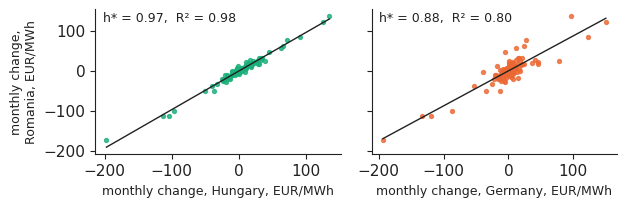

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.25), sharey=True)
for ax, z, col, nm in [(axs[0], 'HU', PAL['HU'], 'Hungary'), (axs[1], 'DE_LU', PAL['DE_LU'], 'Germany')]:
    ax.scatter(dP[z], dP['RO'], s=8, color=col, alpha=0.8)
    xx = np.linspace(dP[z].min(), dP[z].max(), 10)
    ax.plot(xx, HR[z]['h'] * xx, color='#222222', lw=1.0)
    ax.set_xlabel(f'monthly change, {nm}, EUR/MWh', fontsize=9)
    ax.text(0.03, 0.92, f"h* = {HR[z]['h']:.2f},  R² = {HR[z]['r2']:.2f}", transform=ax.transAxes, fontsize=9)
axs[0].set_ylabel('monthly change,\nRomania, EUR/MWh', fontsize=9)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig('hedge_scatter.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()